# 04 Pay: keywords and client countries

| Field | Value |
|---|---|
| **Purpose** | Which title words go with higher or lower pay, and what hourly rates clients in different countries offer |
| **Assignment requirement** | **Task 1** (keyword-salary correlation) and **Task 4** (hourly rates by country, interactive map) |
| **Inputs** | `pay_keywords_hourly.csv`, `pay_keywords_budget.csv`, `pay_keyword_sensitivity.csv`, `pay_countries.csv`, `pay_country_sensitivity.csv`, `pay_prediction.csv` (all from the pipeline's `pay` step), `jobs_clean.parquet`, `job_categories.parquet` |
| **Outputs** | None; the tables above are reused by the database, the API and the dashboard |
| **Build identity** | Printed by the first code cell |

**What "pay" means here (decision D-031)**

- **Hourly pay** is the midpoint of the hourly range a client states, for hourly jobs with a complete range (Notebook 01's `eligible_for_hourly_rate_analysis`).
- **Fixed-price budgets** are a different thing (a total for a whole job, not money per hour). They get a short separate section and are never mixed with hourly rates.
- **Country is the client's country**: the country of the person posting the job, not the freelancer's. Task 4 therefore answers *"what hourly rates do clients in different countries offer?"*
- All results are **associations** ("goes with"), never causes.

**Why logarithms.** Pay has a long right tail (Notebook 02). Models use the natural log of pay, so a model coefficient `b` describes a ratio. It is converted to a percentage with **(exp(b) - 1) x 100**: `b = 0.5` means +64.9%, not +50%.

In [1]:
from job_market.notebook import start

project = start()

RUN_ID: 20261004T114941Z-01ed78f29b
Source: data/raw/all_upwork_jobs_2024-02-07-2024-03-24.csv (244,828 rows)
Taxonomy version: 1.0
Verified outputs: 32 file(s), all hashes match
Environment: matches environment.yml


In [2]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import plotly.io as pio

pio.renderers.default = "plotly_mimetype+notebook_connected"   # interactive in JupyterLab, small notebook file
pd.set_option("display.max_colwidth", 60)
pd.set_option("display.width", 170)

keywords = project.read_csv("pay_keywords_hourly.csv")
budget_keywords = project.read_csv("pay_keywords_budget.csv")
sensitivity = project.read_csv("pay_keyword_sensitivity.csv")
countries = project.read_csv("pay_countries.csv", keep_default_na=False, na_values=[""])
country_sensitivity = project.read_csv("pay_country_sensitivity.csv")
prediction = project.read_csv("pay_prediction.csv")
rules = project.settings.section("pay")

jobs = project.read_parquet("jobs_clean.parquet", columns=[
    "row_id", "country", "hourly_mid", "budget", "eligible_for_hourly_rate_analysis", "eligible_for_budget_analysis"])
hourly = jobs[jobs["eligible_for_hourly_rate_analysis"]]

LAYER_NAMES = {"raw": "raw", "country": "same country", "country_category": "same country + category"}
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
BLUE, ORANGE, AQUA, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#b8b6b0"
plt.rcParams.update({
    "figure.dpi": 110, "axes.edgecolor": MUTED, "axes.labelcolor": INK, "axes.titlesize": 12,
    "axes.titleweight": "bold", "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "xtick.color": MUTED, "ytick.color": MUTED, "font.size": 10, "legend.frameon": False,
})
print(f"Hourly jobs with a complete rate: {len(hourly):,}; median ${hourly['hourly_mid'].median():.2f}/hour")

Hourly jobs with a complete rate: 98,775; median $22.50/hour


## 1. Task 1: which title words go with higher or lower pay?

### 1.1 Which keywords are tested

A *keyword* is a word or a two-word phrase from the job title (`title_key`, which keeps "c++" and "c#"). Stop words are removed and a phrase never jumps over a removed word (decision D-024). A keyword counts **once per job**, however often the title repeats it.

To be tested, a keyword needs:

- at least **300 rated hourly jobs**, so a percentage never rests on a handful of jobs; and
- at least **100 distinct titles** (title keys), so one heavily reposted title cannot carry it.

A single word is dropped when at least 80% of its jobs also contain a kept two-word phrase with that word: "social" mostly appears as "social media", and measuring both would count the same jobs twice.

In [3]:
print(f"Keywords tested (hourly): {len(keywords)}, of which two-word phrases: {(keywords['keyword'].str.contains(' ')).sum()}")
print(f"Smallest support: {keywords['jobs'].min()} jobs, {keywords['title_keys'].min()} distinct titles")
keywords.sort_values("jobs", ascending=False)[["keyword", "jobs", "title_keys", "median_with", "median_without"]].head(12)

Keywords tested (hourly): 322, of which two-word phrases: 51
Smallest support: 300 jobs, 104 distinct titles


,keyword,jobs,title_keys,median_with,median_without
91,developer,7572,5912,25.0,22.5
114,expert,7041,6079,25.5,22.5
303,website,5770,5065,22.5,22.5
88,designer,5603,4560,25.0,22.5
258,specialist,4712,3660,19.5,22.5
87,design,4583,4031,25.0,22.5
290,video,4561,3676,20.0,22.5
171,marketing,4323,3567,20.0,22.5
168,manager,3879,2848,17.5,22.5
30,assistant,3860,2928,9.0,24.0


### 1.2 Three layers, three questions

A keyword can look well paid simply because of **who** posts it or **what kind of job** it belongs to. "Developer" jobs pay more, but US clients post many of them and US clients pay more. So every keyword is measured three times:

| Layer | Question it answers |
|---|---|
| **raw** | Do jobs with this word pay more than jobs without it? |
| **same country** | ...when both are posted by clients in the same country? |
| **same country + category** | ...within the same country *and* the same job function from Notebook 03? |

The third layer needs care. The job category is itself built from the title, so holding it fixed partly removes the very title signal under study ("WordPress" helps make a job *web development*). It answers a narrower question: *inside* web development, do WordPress jobs pay more or less? It is shown **next to** the other two, never as the one correct answer.

**How each layer is computed.** A regression of log pay on the keyword, inside groups of jobs from the same country (and category). Uncertainty is *clustered by title*: repeated postings of one title count as one piece of evidence. Testing 322 keywords makes some look significant by chance, so p-values are adjusted with the **Benjamini-Hochberg false-discovery rate (FDR)**: among keywords called significant at FDR 5%, at most about 5% are expected to be false alarms.

In [4]:
significant = {layer: int((keywords[f"{layer}_p_fdr"] < 0.05).sum()) for layer in LAYER_NAMES}
flips = int(((keywords["raw_pct"] > 0) != (keywords["country_category_pct"] > 0)).sum())
pd.Series({**{f"significant at FDR 5% ({name})": n for name, n in
              zip(LAYER_NAMES.values(), significant.values())},
           "keywords whose sign differs between raw and same country + category": flips}).to_frame("keywords")

,keywords
significant at FDR 5% (raw),244
significant at FDR 5% (same country),243
significant at FDR 5% (same country + category),206
keywords whose sign differs between raw and same country + category,39


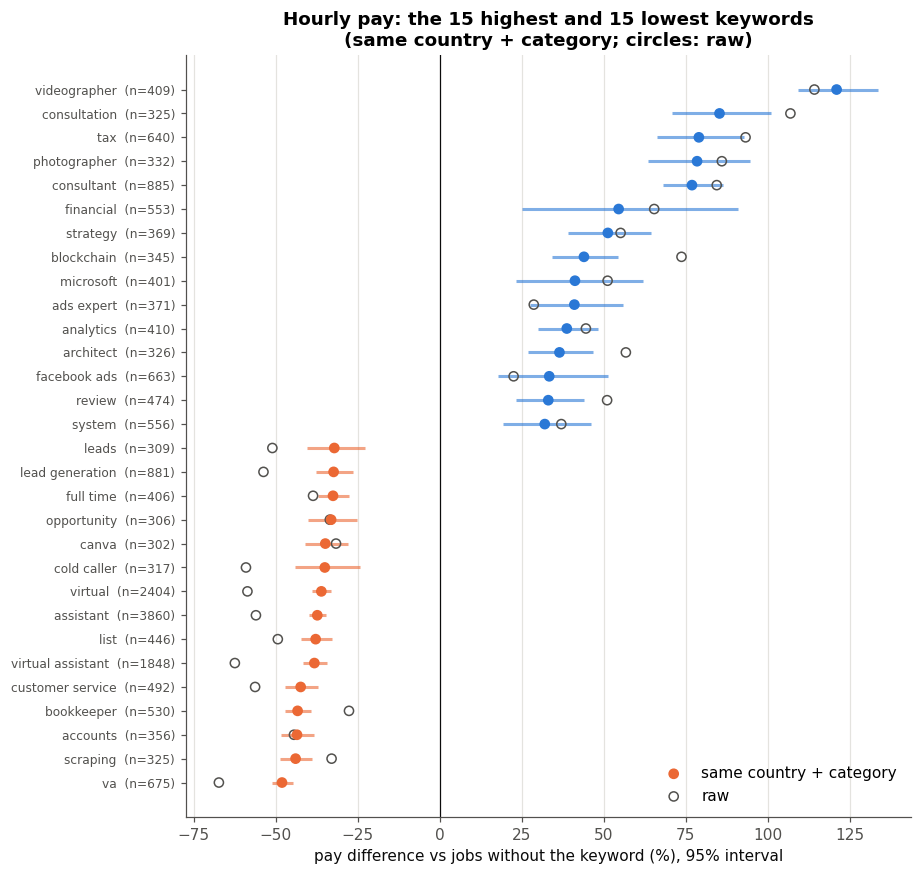

In [5]:
def forest(table, layer, title, n=15):
    top = table.nlargest(n, f"{layer}_pct")
    bottom = table.nsmallest(n, f"{layer}_pct")
    show = pd.concat([bottom, top]).drop_duplicates("keyword").sort_values(f"{layer}_pct")
    fig, ax = plt.subplots(figsize=(8.5, 9))
    y = np.arange(len(show))
    colors = [BLUE if v > 0 else ORANGE for v in show[f"{layer}_pct"]]
    ax.hlines(y, show[f"{layer}_low_pct"], show[f"{layer}_high_pct"], color=colors, lw=2, alpha=0.6)
    ax.scatter(show[f"{layer}_pct"], y, color=colors, zorder=3, label=LAYER_NAMES[layer])
    ax.scatter(show["raw_pct"], y, facecolors="none", edgecolors=MUTED, zorder=2, label="raw")
    ax.axvline(0, color=INK, lw=0.8)
    ax.set_yticks(y)
    ax.set_yticklabels([f"{k}  (n={j})" for k, j in zip(show["keyword"], show["jobs"])], fontsize=8)
    ax.set_xlabel("pay difference vs jobs without the keyword (%), 95% interval")
    ax.set_title(title)
    ax.legend(loc="lower right")
    ax.grid(axis="y", visible=False)
    plt.show()

forest(keywords, "country_category", "Hourly pay: the 15 highest and 15 lowest keywords\n(same country + category; circles: raw)")

In [6]:
columns = ["keyword", "jobs", "median_with", "raw_pct", "country_pct", "country_category_pct",
           "country_category_low_pct", "country_category_high_pct", "country_category_p_fdr"]
print("Highest (same country + category):")
display(keywords.nlargest(10, "country_category_pct")[columns].round(1))
print("Lowest (same country + category):")
keywords.nsmallest(10, "country_category_pct")[columns].round(1)

Highest (same country + category):


,keyword,jobs,median_with,raw_pct,country_pct,country_category_pct,country_category_low_pct,country_category_high_pct,country_category_p_fdr
293,videographer,409,42.5,114.3,110.7,121.1,109.2,133.6,0.0
64,consultation,325,47.5,107.0,104.5,85.3,70.8,101.2,0.0
266,tax,640,50.0,93.3,86.3,79.1,66.2,92.8,0.0
204,photographer,332,37.5,86.1,85.9,78.5,63.6,94.7,0.0
63,consultant,885,40.0,84.5,84.0,76.9,68.0,86.4,0.0
120,financial,553,37.5,65.4,63.8,54.6,25.2,90.9,0.0
263,strategy,369,35.5,55.2,53.7,51.3,39.3,64.4,0.0
37,blockchain,345,37.5,73.7,72.0,44.0,34.3,54.4,0.0
181,microsoft,401,32.5,51.2,48.9,41.3,23.2,62.0,0.0
10,ads expert,371,32.5,28.7,28.8,41.1,27.7,55.9,0.0


Lowest (same country + category):


,keyword,jobs,median_with,raw_pct,country_pct,country_category_pct,country_category_low_pct,country_category_high_pct,country_category_p_fdr
289,va,675,6.5,-67.3,-67.2,-48.1,-51.2,-44.8,0.0
234,scraping,325,16.5,-32.9,-33.2,-43.9,-48.6,-38.8,0.0
5,accounts,356,9.0,-44.4,-42.2,-43.5,-48.4,-38.2,0.0
40,bookkeeper,530,15.0,-27.6,-29.6,-43.3,-47.1,-39.2,0.0
82,customer service,492,8.5,-56.3,-56.5,-42.4,-47.1,-37.2,0.0
296,virtual assistant,1848,7.5,-62.4,-63.0,-38.2,-41.7,-34.5,0.0
162,list,446,10.0,-49.3,-49.8,-37.8,-42.4,-32.9,0.0
30,assistant,3860,9.0,-56.0,-57.0,-37.3,-39.9,-34.7,0.0
295,virtual,2404,7.5,-58.6,-59.2,-36.1,-39.0,-33.0,0.0
58,cold caller,317,7.5,-59.1,-60.0,-35.0,-44.2,-24.4,0.0


**Finding.** The highest premiums go with **advisory and specialist work**: videographer, consultation and consultant, tax, photographer, financial, strategy. Within the same country and category, "consultant" goes with about **+77%** higher hourly rates. The lowest go with **assistant and volume work**: virtual assistant / VA, customer service, lead generation and cold calling, bookkeeping, list building and Canva design; "virtual assistant" goes with about **-38%**.

**Evidence.** The forest chart and tables above; all of these are significant after the FDR adjustment.

### 1.3 How the layers change the story

Most keywords keep their direction, but the size often changes, and for some the meaning changes.

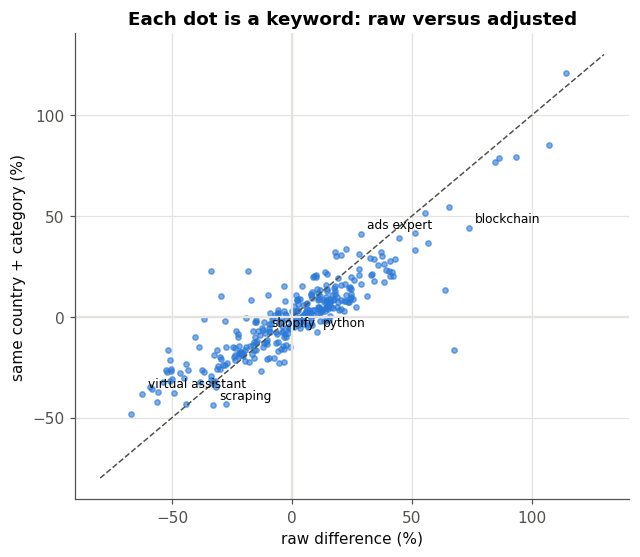

,jobs,raw_pct,country_pct,country_category_pct
keyword,,,,
python,824,10.2,9.9,-7.5
virtual assistant,1848,-62.4,-63.0,-38.2
blockchain,345,73.7,72.0,44.0
ads expert,371,28.7,28.8,41.1
scraping,325,-32.9,-33.2,-43.9
shopify,2323,-11.2,-10.1,-7.9


In [7]:
fig, ax = plt.subplots(figsize=(6.5, 5.5))
ax.scatter(keywords["raw_pct"], keywords["country_category_pct"], s=12, color=BLUE, alpha=0.6)
lim = [-80, 130]
ax.plot(lim, lim, color=MUTED, lw=1, ls="--")
ax.axhline(0, color=GRID)
ax.axvline(0, color=GRID)
for word in ["python", "virtual assistant", "blockchain", "ads expert", "scraping", "shopify"]:
    row = keywords.set_index("keyword").loc[word]
    ax.annotate(word, (row["raw_pct"], row["country_category_pct"]), xytext=(4, 4), textcoords="offset points", fontsize=8)
ax.set_xlabel("raw difference (%)")
ax.set_ylabel("same country + category (%)")
ax.set_title("Each dot is a keyword: raw versus adjusted")
plt.show()
keywords.set_index("keyword").loc[["python", "virtual assistant", "blockchain", "ads expert", "scraping", "shopify"],
                                  ["jobs", "raw_pct", "country_pct", "country_category_pct"]].round(1)

**Reading the chart.** Dots on the dashed line keep the same size after adjustment; dots closer to zero lose part of their raw difference.

- **"python"** goes with **+10%** raw, but **-7.5%** inside the same category: Python jobs sit in well-paid software work, yet *within* software they pay a little less than other software jobs (many are small scripts and scraping tasks).
- **"virtual assistant"** is -62% raw but -38% within its category: part of the low raw figure is simply that assistant work pays less overall.
- **"blockchain"** shrinks from +74% to +44% once the category is held fixed.
- **"ads expert"** grows (+29% raw, +41% adjusted): advertising jobs as a whole pay less, but expert ad jobs pay well inside that group.

Controlling for the client country changes little (the raw and same-country columns are close). Most of the change comes from the category.

### 1.4 Technology and tool names

In [8]:
tools = ["hubspot", "aws", "webflow", "react", "ios", "ai", "android", "figma", "php", "python",
         "shopify", "wordpress", "flutter", "seo", "excel", "canva"]
keywords.set_index("keyword").loc[[t for t in tools if t in set(keywords["keyword"])],
    ["jobs", "median_with", "raw_pct", "country_pct", "country_category_pct",
     "country_category_low_pct", "country_category_high_pct", "country_category_p_fdr"]].sort_values(
    "country_category_pct", ascending=False).round(2)

,jobs,median_with,raw_pct,country_pct,country_category_pct,country_category_low_pct,country_category_high_pct,country_category_p_fdr
keyword,,,,,,,,
hubspot,404,30.0,37.43,34.11,30.03,22.67,37.83,0.00
aws,449,32.5,40.98,40.68,19.96,13.17,27.16,0.00
webflow,579,22.5,13.19,13.80,8.06,2.98,13.40,0.00
react,1098,25.0,11.06,11.71,4.95,0.88,9.19,0.03
ios,410,25.0,16.07,16.48,4.69,-2.31,12.20,0.25
ai,1700,27.5,19.38,18.96,3.18,-1.88,8.49,0.28
android,364,22.5,12.11,13.45,2.70,-4.28,10.19,0.53
figma,558,25.0,7.77,7.30,-0.66,-5.60,4.53,0.83
php,429,25.0,-0.47,0.60,-3.56,-9.03,2.23,0.28


**Finding.** Among tool names, **HubSpot** (+30%) and **AWS** (+20%) go with clearly higher rates within the same country and category. **Shopify**, **WordPress** and **Flutter** go with slightly lower rates (about -8% to -13%), and **SEO**, **Excel** and **Canva** with clearly lower ones (-19% to -35%). Tools that many people can use, and that mark smaller tasks, sit at the bottom. "AI" goes with +19% raw, but its adjusted difference is small and not significant: AI jobs are well paid mostly because of the kind of work they are.

### 1.5 How much do title words explain?

A useful check: if we did not know the title, how well could we guess the pay, and how much do title words add? Models are trained on 80% of title keys and tested on the other 20% (**no title appears on both sides**). Error is shown in dollars per hour (MAE: the average absolute error), and R² on the log scale (the share of pay differences explained: 0 = no better than always guessing the median, 1 = perfect).

In [9]:
prediction[["model", "test_jobs", "mae_usd", "median_abs_error_usd", "r2_log", "title_keys_shared_with_training"]].round(3)

,model,test_jobs,mae_usd,median_abs_error_usd,r2_log,title_keys_shared_with_training
0,median baseline,19469,16.831,10.000,-0.000,0
1,country + category,19469,15.961,9.235,0.109,0
2,country + category + title words,19469,14.797,8.399,0.260,0
3,title words only,19469,14.921,8.426,0.248,0


**Finding.** Client country and job category explain about **11%** of pay differences; adding title words raises this to about **26%**, and title words alone reach about **25%**. The typical error stays large (median about **$8/hour**). Title words carry real information about pay, but **most pay differences come from things the title does not say**: experience level, project size, the freelancer's own profile and negotiation. Every keyword percentage in this notebook should be read with that in mind.

### 1.6 Do the conclusions survive other reasonable choices?

The keyword analysis is repeated five ways: the primary analysis, without flagged extreme rates, without possible reposts, and with the **low** or the **high** end of the range instead of the midpoint.

In [10]:
wide = sensitivity[sensitivity["layer"] == "country_category"].pivot(index="keyword", columns="variant", values="pct")
stability = pd.DataFrame({
    "correlation with primary": wide.corrwith(wide["primary"]).round(3),
    "same direction as primary (%)": (100 * ((wide > 0).eq(wide["primary"] > 0, axis=0)).mean()).round(1),
}).drop(index="primary")
stability

,correlation with primary,same direction as primary (%)
variant,,
high_end_of_range,0.997,98.8
low_end_of_range,0.966,93.5
without_extreme_pay,0.996,99.1
without_possible_reposts,0.994,97.8


**Finding.** The keyword results are very stable: under every variant the percentages correlate at **0.97 or more** with the primary analysis, and at least **93%** keep their direction. Using the low end of the range moves results the most, because low ends are often round minimum rates.

### 1.7 Fixed-price budgets (secondary)

Budgets measure the size of a whole job, not a rate. The same three-layer method gives:

In [11]:
print(f"Budget keywords tested: {len(budget_keywords)}; significant at FDR 5% (same country + category): "
      f"{int((budget_keywords['country_category_p_fdr'] < 0.05).sum())}")
cols = ["keyword", "jobs", "median_with", "raw_pct", "country_category_pct", "country_category_p_fdr"]
display(budget_keywords.nlargest(8, "country_category_pct")[cols].round(1))
budget_keywords.nsmallest(8, "country_category_pct")[cols].round(1)

Budget keywords tested: 340; significant at FDR 5% (same country + category): 240


,keyword,jobs,median_with,raw_pct,country_category_pct,country_category_p_fdr
130,full time,384,700.0,532.5,529.3,0.0
109,expensify,491,500.0,391.8,313.0,0.0
237,saas,479,350.0,267.7,225.6,0.0
9,500,537,500.0,278.1,225.5,0.0
129,full stack,632,300.0,248.4,210.9,0.0
104,engineer,646,300.0,266.4,194.2,0.0
208,platform,693,300.0,179.4,189.4,0.0
235,romance,313,500.0,201.6,187.8,0.0


,keyword,jobs,median_with,raw_pct,country_category_pct,country_category_p_fdr
156,issue,318,30.0,-64.7,-68.6,0.0
121,fix,1040,30.0,-63.8,-68.2,0.0
222,quick,722,25.0,-67.6,-66.3,0.0
264,speakers,515,10.0,-85.0,-65.1,0.0
164,lead generation,954,50.0,-35.3,-64.7,0.0
98,edit,851,25.0,-65.7,-61.6,0.0
279,test,409,25.0,-61.9,-60.1,0.0
168,list,812,50.0,-53.2,-59.2,0.0


**Finding.** For budgets, title words mostly describe **how big the job is**: "full time", "SaaS", "platform", "full stack" and "engineer" go with much larger budgets; "fix", "issue", "quick", "edit" and "test" with much smaller ones. These are differences in job size, not in how well the work is paid per hour, which is why budgets are never compared with hourly rates.

## 2. Task 4: hourly rates by client country

### 2.1 The table

Countries need at least **30 rated hourly jobs** (decision D-020). For each:

- **median rate** and the **middle half** (25th to 75th percentile);
- a **95% interval for the median** from a cluster bootstrap: the data is redrawn many times, whole title groups at a time, and the interval shows how much the median moves;
- a **category-adjusted index**: how the rates of clients in that country compare with the **average client** (all countries, weighted by jobs) **for the same mix of job categories**. +20 means 20% more for the same kinds of work.

In [12]:
print(f"Countries with at least {rules['min_country_jobs']} rated jobs: {len(countries)}; "
      f"they cover {100 * countries['jobs'].sum() / len(hourly):.1f}% of rated jobs")
countries[["country", "jobs", "median_rate", "median_low", "median_high", "p25_rate", "p75_rate",
           "adjusted_index_pct", "adjusted_low_pct", "adjusted_high_pct"]].head(20).round(2)

Countries with at least 30 rated jobs: 91; they cover 97.3% of rated jobs


,country,jobs,median_rate,median_low,median_high,p25_rate,p75_rate,adjusted_index_pct,adjusted_low_pct,adjusted_high_pct
0,United States,46620,25.0,25.0,25.0,15.00,40.00,8.71,8.03,9.35
1,United Kingdom,8113,22.5,22.5,24.0,15.00,35.00,1.82,0.01,4.29
2,Australia,5682,21.0,20.0,22.5,12.50,31.50,-12.13,-13.76,-10.45
3,Canada,5054,22.5,21.0,22.5,12.50,32.50,-6.47,-8.53,-4.37
4,India,4337,20.0,18.0,20.0,12.50,27.50,-20.63,-22.47,-18.78
5,Germany,2022,24.0,22.5,25.0,15.00,35.00,0.74,-1.80,3.17
6,Netherlands,1554,20.0,20.0,20.0,11.12,29.50,-16.20,-19.10,-13.17
7,Pakistan,1379,20.0,17.5,20.0,12.50,27.25,-15.29,-19.38,-11.76
8,United Arab Emirates,1227,22.5,22.5,22.5,12.50,32.50,-5.98,-9.88,-1.07
9,France,1213,21.0,20.0,22.5,12.50,30.00,-12.43,-15.76,-8.99


**About the narrow median intervals.** Clients choose round numbers ($15, $20, $25), so many jobs share exactly the same rate. For large countries the median then sits on one of these values in every bootstrap round, and the interval collapses to a single number (for the United States, exactly $25). That is a real feature of the data, not a calculation error.

### 2.2 Interactive map

Hover over a country to see its median rate, middle half, number of jobs and adjusted index. Countries with fewer than 30 rated jobs are left grey. (The map is interactive in JupyterLab; the static chart below shows the same numbers.)

In [13]:
mapped = countries[countries["iso3"].notna() & (countries["iso3"] != "")]
missing_code = sorted(set(countries["country"]) - set(mapped["country"]))
print(f"Countries without a map code: {missing_code if missing_code else 'none'}")
hover = [f"<b>{c}</b><br>median ${m:.2f}/h<br>middle half ${a:.2f}-${b:.2f}<br>jobs: {n:,}<br>"
         f"category-adjusted index: {i:+.0f}%" for c, m, a, b, n, i in
         zip(mapped["country"], mapped["median_rate"], mapped["p25_rate"], mapped["p75_rate"], mapped["jobs"],
             mapped["adjusted_index_pct"])]
figure = go.Figure(go.Choropleth(
    locations=mapped["iso3"], z=mapped["median_rate"], text=hover, hoverinfo="text",
    colorscale="Blues", marker_line_color="white", marker_line_width=0.4,
    colorbar_title="median $/h",
))
figure.update_layout(title="Median hourly rate offered by clients, by client country (30+ rated jobs)",
                     geo=dict(showframe=False, projection=dict(type="natural earth")),
                     margin=dict(l=0, r=0, t=50, b=0), height=480)
figure.show()

Countries without a map code: none


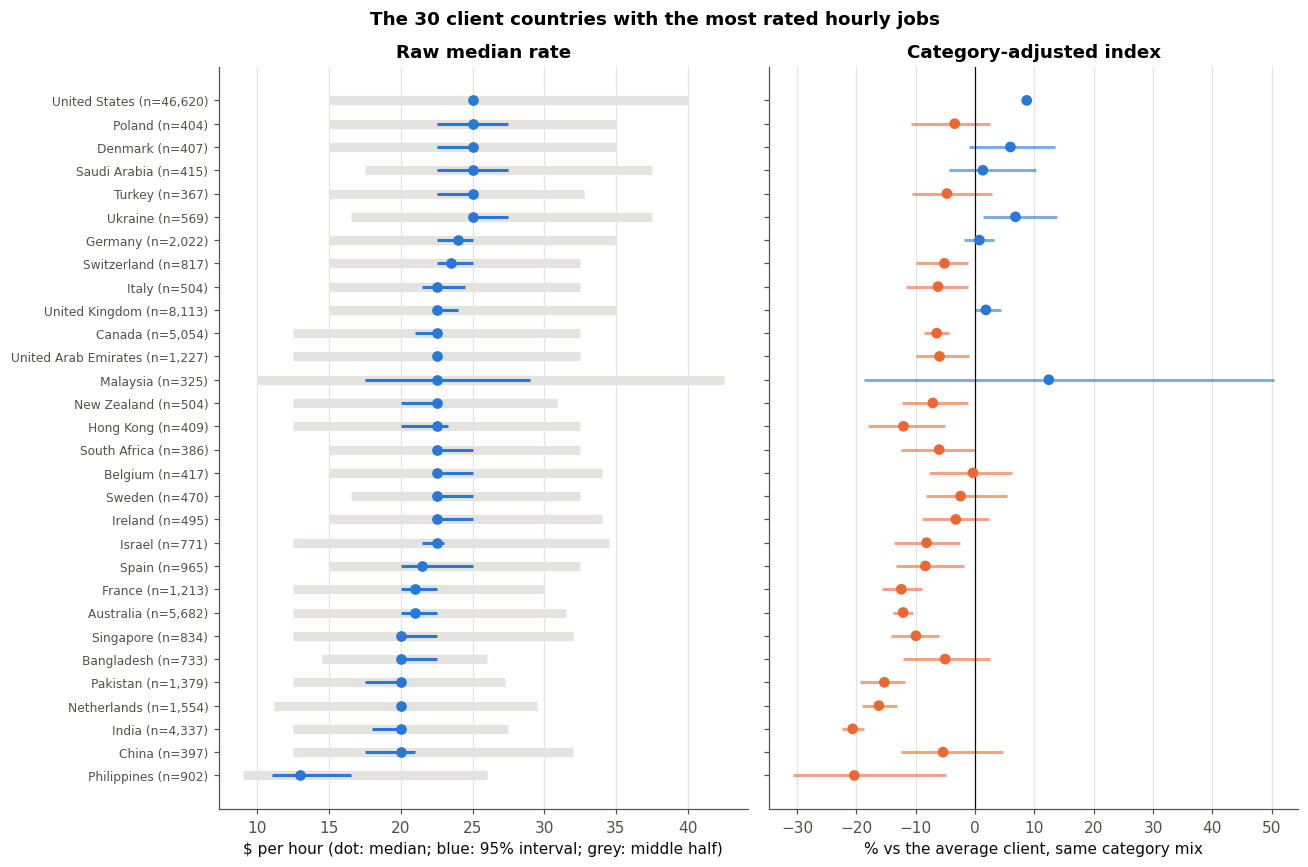

In [14]:
big = countries.nlargest(30, "jobs").sort_values("median_rate")
fig, axes = plt.subplots(1, 2, figsize=(12, 8), sharey=True)
y = np.arange(len(big))
axes[0].hlines(y, big["p25_rate"], big["p75_rate"], color=GRID, lw=6)
axes[0].hlines(y, big["median_low"], big["median_high"], color=BLUE, lw=2)
axes[0].scatter(big["median_rate"], y, color=BLUE, zorder=3)
axes[0].set_yticks(y)
axes[0].set_yticklabels([f"{c} (n={n:,})" for c, n in zip(big["country"], big["jobs"])], fontsize=8)
axes[0].set_xlabel("$ per hour (dot: median; blue: 95% interval; grey: middle half)")
axes[0].set_title("Raw median rate")
colors = [BLUE if v >= 0 else ORANGE for v in big["adjusted_index_pct"]]
axes[1].hlines(y, big["adjusted_low_pct"], big["adjusted_high_pct"], color=colors, lw=2, alpha=0.6)
axes[1].scatter(big["adjusted_index_pct"], y, color=colors, zorder=3)
axes[1].axvline(0, color=INK, lw=0.8)
axes[1].set_xlabel("% vs the average client, same category mix")
axes[1].set_title("Category-adjusted index")
for ax in axes:
    ax.grid(axis="y", visible=False)
fig.suptitle("The 30 client countries with the most rated hourly jobs", fontweight="bold")
fig.tight_layout()
plt.show()

**Finding.**

- Clients in the **United States** offer a median of **$25/hour**, and **+9%** more than the average client for the same mix of work. The **United Kingdom**, **Germany** and **Switzerland** are close to the average.
- Clients in **India** (median $20) and the **Philippines** (median $13) offer about **20% less** than the average client for the same kinds of work.
- Some raw and adjusted views disagree. **Australian** clients have a median near the overall one ($21), but offer about **12% less** for the same mix of work: they post more of the better-paid kinds of jobs. The category mix matters.
- East Asian clients (**South Korea**, **Japan**, **Taiwan**) offer clearly less (about -28% to -48%), though with wider intervals.

Medians differ much less between countries than the spread *within* each country (the grey middle-half bars): the country of the client says less about a job's rate than the job itself.

### 2.3 Do the country medians survive other choices?

In [15]:
wide_c = country_sensitivity.pivot(index="country", columns="variant", values="median_rate")
order = countries.nlargest(10, "jobs")["country"]
wide_c.loc[order, ["primary", "without_extreme_pay", "without_possible_reposts", "low_end_of_range", "high_end_of_range"]]

variant,primary,without_extreme_pay,without_possible_reposts,low_end_of_range,high_end_of_range
country,,,,,
United States,25.0,25.0,25.0,15.0,35.0
United Kingdom,22.5,22.5,22.5,12.0,30.0
Australia,21.0,20.5,21.0,12.0,30.0
Canada,22.5,22.5,22.5,13.0,30.0
India,20.0,19.5,20.0,10.0,25.0
Germany,24.0,24.0,24.5,15.0,35.0
Netherlands,20.0,20.0,20.0,10.0,30.0
Pakistan,20.0,20.0,20.0,10.0,26.0
United Arab Emirates,22.5,22.5,22.5,13.0,30.0


In [16]:
rank_corr = wide_c.rank().corr(method="pearson")["primary"].drop("primary").round(3)
rank_corr.to_frame("rank correlation with primary (all countries)")

,rank correlation with primary (all countries)
variant,
high_end_of_range,0.900
low_end_of_range,0.686
without_extreme_pay,0.990
without_possible_reposts,0.964


**Finding.** Removing extreme rates or possible reposts leaves the medians practically unchanged (rank correlation 0.96 or more). The **high end** of the range keeps the country ranking similar (0.90). The **low end** reorders countries more (0.69): low ends are mostly round minimum rates ($10, $15), so many countries tie and small changes reorder them. The big picture holds under every choice: US clients offer the most among large markets, and South Asian, South-East Asian and East Asian clients offer less; but fine-grained rankings of mid-sized countries should not be read too precisely.

## 3. Summary

**Task 1 (keywords and pay)**

- 322 title keywords with enough support were tested in three layers; about two-thirds remain significant at FDR 5% even within the same country and category.
- Advisory and specialist words (consultant, consultation, tax, financial, strategy, videographer) go with clearly higher rates; assistant and volume-work words (virtual assistant, customer service, lead generation, list, Canva) with clearly lower ones.
- Holding the job category fixed changes the story for some words ("python": +10% raw, -7.5% within category).
- Title words explain about a quarter of the variation in hourly pay; most of it lies outside the title.
- Results are stable across five reasonable analysis choices.

**Task 4 (client countries)**

- 91 client countries have at least 30 rated jobs; US clients offer the highest typical rate among large markets ($25 median, +9% adjusted).
- Category mix explains part of the country differences (Australia: near-average median, -12% for the same work).
- An interactive map and a static chart show both views.

**Limits**

- Associations, not causes. A keyword may stand for unmeasured things (experience level, project size).
- Pay is what clients **offer** in the posting, not what freelancers finally earn.
- The category control inherits Notebook 03's weakness: Software, AI and Engineering titles are often in *Other*, so within-category comparisons for those functions are less precise.

## 4. Claims check

Every number quoted in this notebook's text, checked against the data:

In [17]:
kw = keywords.set_index("keyword")
ct = countries.set_index("country")
pred = prediction.set_index("model")
claims = {
    "322 keywords": len(keywords) == 322,
    "about two-thirds significant within country+category": 0.6 <= significant["country_category"] / len(keywords) <= 0.7,
    "consultant about +77%": round(kw.loc["consultant", "country_category_pct"]) == 77,
    "virtual assistant about -38%": round(kw.loc["virtual assistant", "country_category_pct"]) == -38,
    "python +10% raw, -7.5% within": (round(kw.loc["python", "raw_pct"]) == 10
                                      and round(kw.loc["python", "country_category_pct"], 1) == -7.5),
    "virtual assistant -62% raw": round(kw.loc["virtual assistant", "raw_pct"]) == -62,
    "blockchain +74% -> +44%": (round(kw.loc["blockchain", "raw_pct"]), round(kw.loc["blockchain", "country_category_pct"])) == (74, 44),
    "ads expert +29% -> +41%": (round(kw.loc["ads expert", "raw_pct"]), round(kw.loc["ads expert", "country_category_pct"])) == (29, 41),
    "hubspot +30%, aws +20%": (round(kw.loc["hubspot", "country_category_pct"]), round(kw.loc["aws", "country_category_pct"])) == (30, 20),
    "shopify/wordpress/flutter -8% to -13%": all(-13.5 <= kw.loc[w, "country_category_pct"] <= -7.5
                                                for w in ["shopify", "wordpress", "flutter"]),
    "seo/excel/canva -19% to -35%": all(-35.5 <= kw.loc[w, "country_category_pct"] <= -19 for w in ["seo", "excel", "canva"]),
    "ai +19% raw, adjusted not significant": (round(kw.loc["ai", "raw_pct"]) == 19 and kw.loc["ai", "country_category_p_fdr"] > 0.05),
    "controls explain about 11%": round(100 * pred.loc["country + category", "r2_log"]) == 11,
    "with title words about 26%": round(100 * pred.loc["country + category + title words", "r2_log"]) == 26,
    "title words alone about 25%": round(100 * pred.loc["title words only", "r2_log"]) == 25,
    "median error about $8": round(pred.loc["country + category + title words", "median_abs_error_usd"]) == 8,
    "no shared title keys in the split": int(pred["title_keys_shared_with_training"].max()) == 0,
    "sensitivity correlations >= 0.97": bool((stability["correlation with primary"] >= 0.965).all()),
    "sensitivity same direction >= 93%": bool((stability["same direction as primary (%)"] >= 93).all()),
    "91 countries": len(countries) == 91,
    "US median $25, about +9%": (ct.loc["United States", "median_rate"] == 25 and round(ct.loc["United States", "adjusted_index_pct"]) == 9),
    "US median interval is exactly $25": ct.loc["United States", "median_low"] == ct.loc["United States", "median_high"] == 25,
    "India $20 and Philippines $13, about -20%": (ct.loc["India", "median_rate"] == 20 and ct.loc["Philippines", "median_rate"] == 13
                                                 and all(-22 <= ct.loc[c, "adjusted_index_pct"] <= -19 for c in ["India", "Philippines"])),
    "Australia $21, about -12%": ct.loc["Australia", "median_rate"] == 21 and round(ct.loc["Australia", "adjusted_index_pct"]) == -12,
    "UK, Germany, Switzerland close to average": all(abs(ct.loc[c, "adjusted_index_pct"]) < 6
                                                     for c in ["United Kingdom", "Germany", "Switzerland"]),
    "Korea/Japan/Taiwan -28% to -48%": all(-48.5 <= ct.loc[c, "adjusted_index_pct"] <= -28
                                           for c in ["South Korea", "Japan", "Taiwan"]),
    "extremes/reposts rank correlation >= 0.96": bool(rank_corr[["without_extreme_pay", "without_possible_reposts"]].min() >= 0.96),
    "high end 0.90, low end 0.69": (round(rank_corr["high_end_of_range"], 2), round(rank_corr["low_end_of_range"], 2)) == (0.90, 0.69),
}
claims = pd.Series(claims, name="true").to_frame()
assert claims["true"].all(), claims[~claims["true"]]
claims

,true
322 keywords,True
about two-thirds significant within country+category,True
consultant about +77%,True
virtual assistant about -38%,True
"python +10% raw, -7.5% within",True
virtual assistant -62% raw,True
blockchain +74% -> +44%,True
ads expert +29% -> +41%,True
"hubspot +30%, aws +20%",True
shopify/wordpress/flutter -8% to -13%,True
